# 03 · Hillsborough COVID cases

**Requirement 3 · 5 points · moving-average columns and a daily-cases line**

The daily series reveals short-term variation; the moving average makes the longer trend easier to follow. Columns show the supplied moving average, with daily cases overlaid as the required line. Both series use one cases-per-day axis; a second axis would give identical units different visual scales.

**Source:** `data/Combined.xlsx`, `Hillsborough` worksheet. Dates are event dates, not download dates. These are raw case counts, not population-adjusted comparisons.

**Source-specific detail:** the supplied average reproduces an **8-observation trailing mean**, current observation included, with partial initial windows. Hillsborough matches exactly; Pasco differs by no more than 0.05 because of displayed one-decimal rounding. It is not relabeled as a 7-day average.

Daily dates absent from the sheet are reintroduced as **missing**, not zero. The original supplied average stays unchanged; the displayed lines have gaps for unlisted dates.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'config').is_dir() else Path.cwd().parent
assert (ROOT / 'config/assignment.json').is_file(), 'Open from the repository or notebooks directory.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from dv_assignment.data import config
from dv_assignment.data import course_county, audit_daily_series, daily_preview
from dv_assignment import charts


## Load and validate the actual course worksheet

The loader checks dates, duplicate keys, numeric values, and every supplied moving average against its observed source formula. The code is in `dv_assignment/data.py`; the plotting code is in `dv_assignment/charts.py`.

In [2]:
data = course_county(config()['covid'], 'Hillsborough')
print({key: value for key, value in data.attrs.items() if key != 'unlisted_dates'})
display(daily_preview(data))
print(f"Observed days: {data.daily_cases.notna().sum():,}")
print(f"Cases across listed dates: {data.daily_cases.sum():,.0f}")
print(f"Unlisted calendar dates: {data.attrs['missing_calendar_days']}")

{'county': 'Hillsborough', 'state': 'Florida', 'average_definition': 'Supplied 8-observation trailing average', 'missing_calendar_days': 1, 'average_supplied': True, 'negative_daily_revisions': 0, 'source': 'Combined.xlsx', 'average_validation': 'All supplied values reproduced within source rounding precision'}


,daily_cases,moving_average
date,,
2020-03-01 00:00:00,2,2.00
2020-03-02 00:00:00,Not listed,Not listed
2020-03-03 00:00:00,2,2.00
2020-03-04 00:00:00,1,1.67
2020-03-05 00:00:00,3,2.00
2020-03-06 00:00:00,3,2.20
2020-03-07 00:00:00,2,2.17
2020-03-08 00:00:00,5,2.57
2020-03-09 00:00:00,6,3.00


Observed days: 370
Cases across listed dates: 113,597
Unlisted calendar dates: 1


## Missing-value check and treatment

`isna()` checks NaN, None and pandas NA. The audit separates null values on original observed dates from the additional calendar dates inserted for display. There are no missing case counts or supplied means on the original worksheet rows. The table preview labels inserted gaps **Not listed**; the underlying values remain missing. We do not replace them with zero, interpolate counts, or carry a previous mean into an unlisted date.

In [3]:
null_audit, unlisted_dates = audit_daily_series(data)
display(null_audit)
display(unlisted_dates)
assert null_audit.nulls_on_observed_dates.eq(0).all()
(ROOT / 'reports').mkdir(exist_ok=True)
null_audit.to_csv(ROOT / 'reports' / f"{data.attrs['county'].lower()}_null_audit.csv", index=False)

,county,field,nulls_on_observed_dates,inserted_unlisted_dates,total_display_nulls
0,Hillsborough,daily_cases,0,1,1
1,Hillsborough,moving_average,0,1,1


,county,date,reason
0,Hillsborough,2020-03-02,Date absent from the selected source; not auto...


## Required visualization

Blue and orange separate the series with strong contrast. The source note defines the moving average, the y-axis starts at zero, and date ticks remain readable across the complete period.

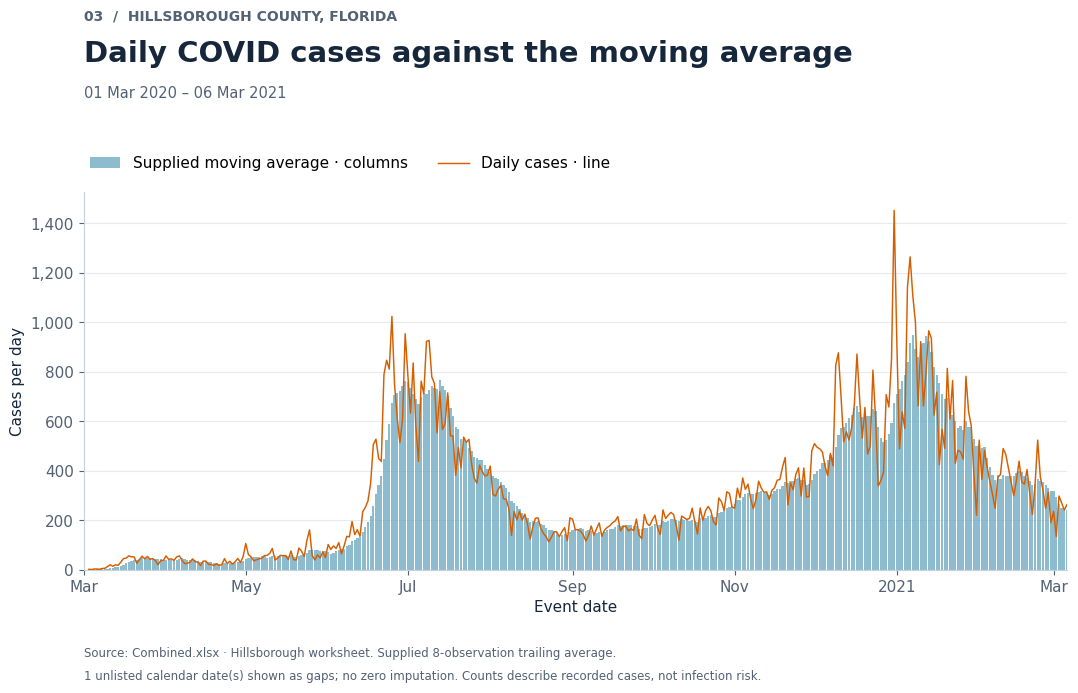

In [4]:
fig = charts.hillsborough(data)
charts.export(fig, ROOT / 'figures', '03_hillsborough_covid')
plt.show()

## Read the result

Use the table below to verify the highest recorded day and peak supplied average. The moving average smooths recorded variation; it is not a forecast. Missing dates are not evidence of zero cases. Changes in testing and case recording can affect the daily series.

In [5]:
print(f"Highest recorded daily count: {data.daily_cases.max():,.0f} on {data.daily_cases.idxmax():%d %b %Y}")
print(f"Highest supplied moving average: {data.moving_average.max():,.1f} on {data.moving_average.idxmax():%d %b %Y}")

Highest recorded daily count: 1,453 on 31 Dec 2020
Highest supplied moving average: 948.1 on 07 Jan 2021
